# American options: Longstaff-Schwartz vs. tree vs. PDE

Checks on `pricing.lsm`, using `pricing.binomial` and `pricing.pde` (American) as references:

1. **Three methods, one price**: American put by tree, PDE and LSM.
2. **Early-exercise premium** as a function of spot, and where it is optimal to exercise.
3. **Bias of LSM**: it should land *below* the true value; how that gap depends on the number of exercise dates and on the regression basis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricing.binomial import binomial_price
from pricing.black_scholes import black_scholes_price
from pricing.lsm import lsm_price
from pricing.pde import pde_price

In [2]:
# Market parameters (same as previous notebooks, for comparability)
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
q = 0.02

## 1. Three methods, one price

In [3]:
european = black_scholes_price(S0, K, T, r, sigma, "put", q)
tree = binomial_price(S0, K, T, r, sigma, "put", q, n_steps=3000, exercise_style="american")
pde = pde_price(S0, K, T, r, sigma, "put", q, exercise_style="american", n_space=800, n_time=800)
lsm = lsm_price(S0, K, T, r, sigma, "put", q, n_paths=300_000, n_steps=50, degree=3, seed=7)

print(f"European put (Black-Scholes):      {european:.5f}")
print(f"American put, binomial 3000 steps: {tree:.5f}")
print(f"American put, PDE 800 x 800:       {pde:.5f}")
print(f"American put, LSM 300k x 50:       {lsm.price:.5f}   SE {lsm.std_error:.5f}   95% CI [{lsm.ci_lower:.5f}, {lsm.ci_upper:.5f}]")
print(f"Early-exercise premium (tree - European): {tree - european:.5f}")

European put (Black-Scholes):      6.33008
American put, binomial 3000 steps: 6.66038
American put, PDE 800 x 800:       6.66018
American put, LSM 300k x 50:       6.66168   SE 0.01417   95% CI [6.63391, 6.68945]
Early-exercise premium (tree - European): 0.33030


The tree (6.6604) and the PDE (6.6602) agree to 2e-4, and LSM (6.6617, SE 0.014) is within 0.1 standard errors of both. The American put is worth 0.330 more than the European one at the money, about 5% of the price.

## 2. Early-exercise premium and the exercise region

The American put is worth at least its intrinsic value $K-S$. For low enough spot, the value of waiting (interest on the strike earned by exercising now, minus optionality lost) turns negative and the option is exercised: there the American price *equals* intrinsic value. The boundary $S^*(\tau)$ separates the exercise and continuation regions.

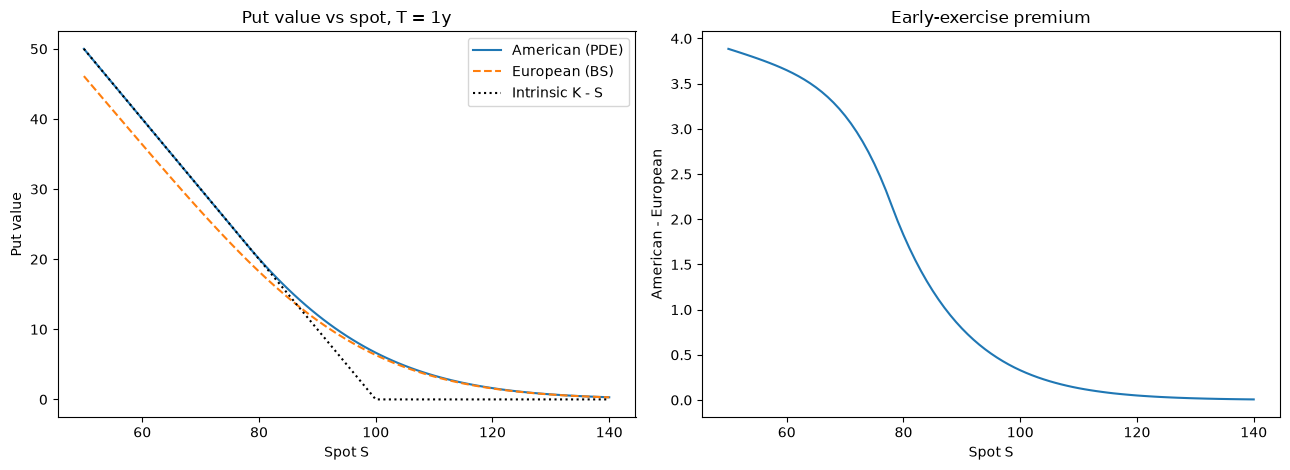

Largest spot on the grid where American = intrinsic (T = 1y): about 78.0
Premium is largest at S = 50.0: 3.8853


In [4]:
spots = np.linspace(50, 140, 91)
amer = np.array([pde_price(s, K, T, r, sigma, "put", q, "american", n_space=500, n_time=500) for s in spots])
euro = np.array([black_scholes_price(s, K, T, r, sigma, "put", q) for s in spots])
intrinsic = np.maximum(K - spots, 0.0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(spots, amer, label="American (PDE)")
axes[0].plot(spots, euro, "--", label="European (BS)")
axes[0].plot(spots, intrinsic, ":", color="k", label="Intrinsic K - S")
axes[0].set_xlabel("Spot S"); axes[0].set_ylabel("Put value"); axes[0].set_title("Put value vs spot, T = 1y"); axes[0].legend()
axes[1].plot(spots, amer - euro)
axes[1].set_xlabel("Spot S"); axes[1].set_ylabel("American - European"); axes[1].set_title("Early-exercise premium")
fig.tight_layout()
plt.show()

in_exercise = (amer - intrinsic) < 1e-6
s_star = spots[in_exercise].max() if in_exercise.any() else np.nan
print(f"Largest spot on the grid where American = intrinsic (T = 1y): about {s_star:.1f}")
print(f"Premium is largest at S = {spots[np.argmax(amer - euro)]:.1f}: {np.max(amer - euro):.4f}")

On the grid, American equals intrinsic value for $S\le 78$ at $T=1$. The premium keeps growing as spot falls (largest at the edge of the grid, $S=50$: 3.89), because deep in the money the European put is priced below $K-S$ (it cannot collect the strike early) while the American one is not.

In [5]:
# Exercise boundary at t = 0 as a function of the time left, and its dependence on the interest rate.
maturities = [0.1, 0.25, 0.5, 1.0, 2.0]
spot_grid = np.arange(40, 100.01, 0.5)

def boundary(T_, r_):
    vals = np.array([pde_price(s, K, T_, r_, sigma, "put", q, "american", n_space=400, n_time=300) for s in spot_grid])
    hit = (vals - np.maximum(K - spot_grid, 0.0)) < 1e-6
    return spot_grid[hit].max() if hit.any() else np.nan

rows = [{"T": T_, **{f"r={r_:.0%}": boundary(T_, r_) for r_ in (0.01, 0.05, 0.10)}} for T_ in maturities]
df_b = pd.DataFrame(rows).set_index("T")
df_b

,r=1%,r=5%,r=10%
T,,,
0.10,48.0,89.0,91.5
0.25,47.0,85.0,89.0
0.50,46.0,81.5,87.0
1.00,44.0,78.0,85.0
2.00,41.5,74.5,83.5


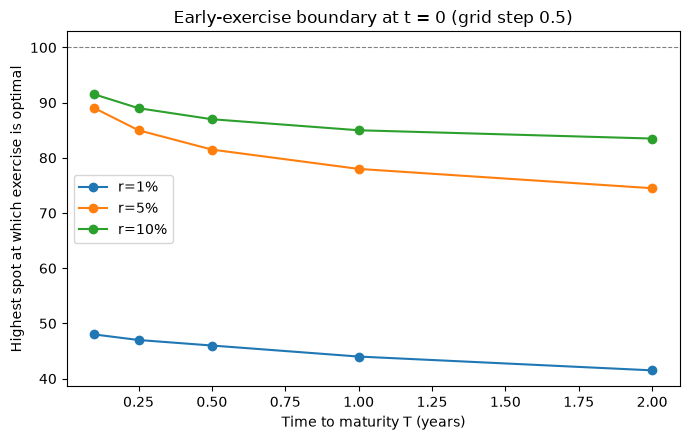

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for col in df_b.columns:
    ax.plot(df_b.index, df_b[col], "o-", label=col)
ax.axhline(K, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Time to maturity T (years)")
ax.set_ylabel("Highest spot at which exercise is optimal")
ax.set_title("Early-exercise boundary at t = 0 (grid step 0.5)")
ax.legend()
fig.tight_layout()
plt.show()

**Reading the boundary**

- It rises towards the strike as maturity shrinks and falls as there is more time left (at $r=5\%$: 89 for 0.1y, 78 for 1y, 74.5 for 2y): more time means more optionality to lose by exercising.
- Higher rates move it up (at $T=1$: 44, 78, 85 for $r=1\%, 5\%, 10\%$): the interest earned on the strike is the reason to exercise a put early.
- With $r=1\%<q=2\%$ the boundary is far below the strike (48 at 0.1y). The limit for $T\to0$ is $K\min(1, r/q)$, which is $50$ for $r=1\%$ and $K$ for the other two rates; the table is consistent with that (48 for 0.1y at $r=1\%$ against a limit of 50; the other two columns approach $K=100$ more slowly).
- The values are limited by the 0.5 spot grid and by the projection-based PDE, so read them to within about one grid step.

## 3. LSM is biased low

The regression-based exercise rule is a *feasible* strategy, so its expected payoff cannot exceed the optimal one. There are two separate sources of low bias, and the experiment below mixes them:

- Only `n_steps` exercise dates exist (a Bermudan option), which is worth less than the American one. This disappears as `n_steps` grows.
- The polynomial basis approximates the continuation value badly, so the rule exercises at the wrong times. This disappears as the basis improves.

The reference is the 3000-step tree.

In [7]:
rows = []
for n_steps in [4, 8, 16, 32, 64]:
    res = lsm_price(S0, K, T, r, sigma, "put", q, n_paths=300_000, n_steps=n_steps, degree=3, seed=21)
    rows.append({"dates": n_steps, "degree": 3, "LSM": res.price, "SE": res.std_error, "LSM - tree": res.price - tree})
for degree in [1, 2, 3, 5]:
    res = lsm_price(S0, K, T, r, sigma, "put", q, n_paths=300_000, n_steps=50, degree=degree, seed=21)
    rows.append({"dates": 50, "degree": degree, "LSM": res.price, "SE": res.std_error, "LSM - tree": res.price - tree})
df_lsm = pd.DataFrame(rows)
print(f"tree reference: {tree:.5f}")
df_lsm.round(5)

tree reference: 6.66038


,dates,degree,LSM,SE,LSM - tree
0,4,3,6.57263,0.01485,-0.08775
1,8,3,6.62936,0.01456,-0.03102
2,16,3,6.63410,0.01438,-0.02628
3,32,3,6.63322,0.01418,-0.02716
4,64,3,6.67263,0.01411,0.01225
5,50,1,6.58953,0.01468,-0.07085
6,50,2,6.64000,0.01405,-0.02038
7,50,3,6.65247,0.01409,-0.00791
8,50,5,6.65639,0.01411,-0.00399


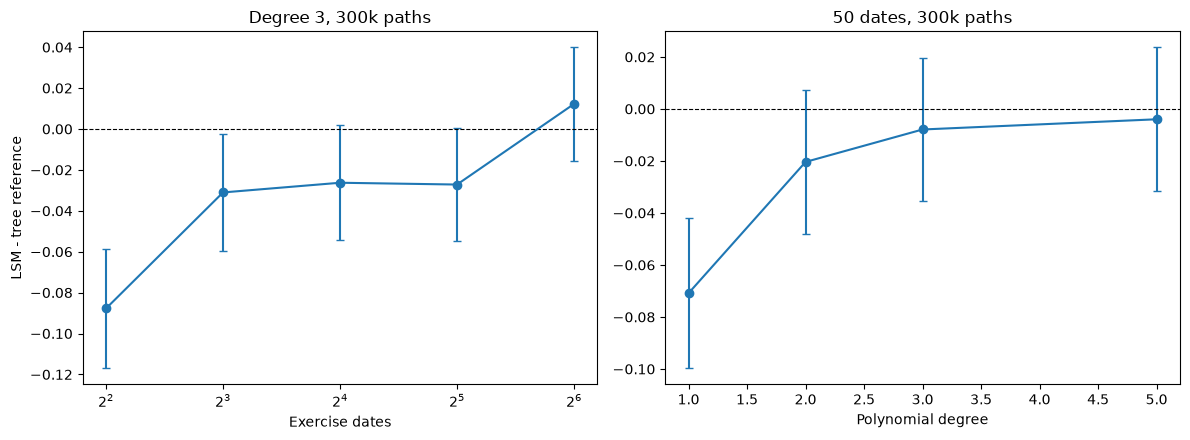

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
a = df_lsm[df_lsm["degree"] == 3].iloc[:5]
axes[0].errorbar(a["dates"], a["LSM - tree"], yerr=1.96 * a["SE"], fmt="o-", capsize=3)
axes[0].axhline(0, color="k", linestyle="--", linewidth=0.8)
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("Exercise dates"); axes[0].set_ylabel("LSM - tree reference"); axes[0].set_title("Degree 3, 300k paths")
b = df_lsm.iloc[5:]
axes[1].errorbar(b["degree"], b["LSM - tree"], yerr=1.96 * b["SE"], fmt="o-", capsize=3)
axes[1].axhline(0, color="k", linestyle="--", linewidth=0.8)
axes[1].set_xlabel("Polynomial degree"); axes[1].set_title("50 dates, 300k paths")
fig.tight_layout()
plt.show()

**What the experiment shows**

The standard error is 0.014 for every row, so differences smaller than about 0.03 are not distinguishable from noise.

- **Few exercise dates hurt**: 4 dates give $-0.088$ (6 SE). That is mostly the Bermudan-vs-American gap, not a bad regression. 8, 16 and 32 dates give $-0.031$, $-0.026$ and $-0.027$ (about 2 SE each, so only weakly distinguishable from zero), and the 64-date run is $+0.012$, above the reference. That is not a contradiction: low bias is a statement about the expectation, a particular run can fall on either side.
- **A poor basis hurts more than it looks**: with 50 dates, degree 1 (a straight line for the continuation value) gives $-0.071$ (5 SE), degree 2 $-0.020$, degree 3 $-0.008$, degree 5 $-0.004$. The last two are within noise. A straight line cannot represent the convex continuation value, so it exercises too late or too early on the wrong paths.

Two honest limits: with 300k paths I cannot resolve a bias below a few hundredths, so these runs do not show *how small* the bias gets at high degree. And a larger basis is not free: with fewer paths in the money, the regression itself starts overfitting, which pushes the estimate up (the in-sample optimum), not down; that effect is not explored here.